In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("homeprices_banglore.csv")
df.head()

,area,bedrooms,price
0,1056,2,39.07
1,2600,4,120.00
2,1440,3,62.00
3,1521,3,75.00
4,1200,2,51.00


In [3]:
from sklearn.preprocessing import MinMaxScaler
sx = MinMaxScaler()
sy = MinMaxScaler()

scaled_x = sx.fit_transform(df.drop("price", axis=1))
scaled_y = sy.fit_transform(df[["price"]])

w = np.ones(shape = scaled_x.shape[1])
np.transpose(scaled_x).shape

(2, 20)

In [4]:
def batch_gradient_descent(X, y_true, epochs, learning_rate = 0.01):
    w = np.ones(shape = X.shape[1])
    y_true = np.array(y_true).reshape(-1)
    b = 0
    total_samples = X.shape[0]
    loss = 0

    cost_list = []
    epoch_list = []

    for e in range(epochs):
        y_pred = np.dot(X, w) + b

        error = y_true - y_pred
        w_grad = -(2 / total_samples) * (np.dot(np.transpose(X), error))
        b_grad = -(2 / total_samples) * np.sum(error)

        w = w - (learning_rate * w_grad)
        b = b - (learning_rate * b_grad)

        loss = np.mean(np.square(error))

        if e % 10 == 0:
            cost_list.append(loss)
            epoch_list.append(e)
    return w, b, loss, cost_list, epoch_list

w, b, loss, cost_list, epoch_list = batch_gradient_descent(scaled_x, scaled_y, 500, 0.1)
w, b, loss

(array([0.75550442, 0.41573953]),
 np.float64(-0.11682769564715854),
 np.float64(0.0034268126227234427))

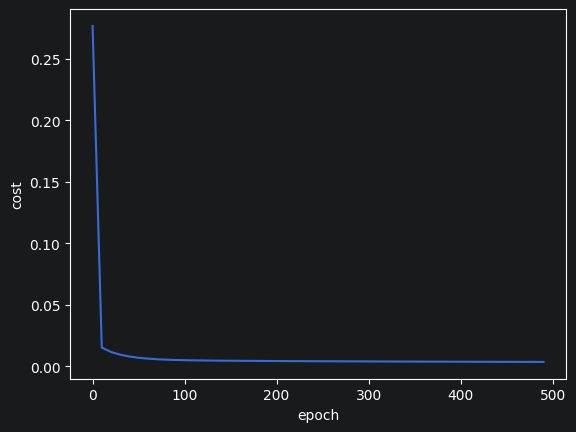

In [5]:
plt.xlabel("epoch")
plt.ylabel("cost")
plt.plot(epoch_list, cost_list)

In [6]:
def predict(area, bedroom, w, b):
    scaled_x = sx.transform([[area, bedroom]])[0]
    print(b)

    scaled_price = w[0] * scaled_x[0] + w[1] * scaled_x[1] + b
    return sy.inverse_transform([[scaled_price]])[0][0]

predict(1800, 3, w, b)

-0.11682769564715854


D:\Data Science\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


np.float64(79.4607127593908)

In [18]:
import random

def stochastic_gradient_descent(X, y_true, epochs, learning_rate = 0.01):
    cost_list = []
    epoch_list = []

    y_true = np.array(y_true).reshape(-1)
    w = np.ones(shape = X.shape[1])
    b = 0
    total_samples = X.shape[0]
    loss = 0
    for e in range(epochs):
        random_index = random.randint(0, total_samples - 1)
        sample_x = X[random_index]
        sample_y = y_true[random_index]
        y_pred = np.dot(sample_x, w) + b
        error = sample_y - y_pred

        w_grad = -(2 / total_samples) * (np.dot(np.transpose(X), error))
        b_grad = -(2 / total_samples) * np.sum(error)

        print(w_grad.shape)

        w = w - (learning_rate * w_grad)
        b = b - (learning_rate * b_grad)

        loss = np.mean(np.square(error))

        if e % 100 == 0:
            cost_list.append(loss)
            epoch_list.append(e)
    return w, b, loss, cost_list, epoch_list

print(scaled_x.shape)
w_sgd, b_sgd, loss, cost_list, epoch_list = stochastic_gradient_descent(scaled_x, scaled_y, 500, 0.1)

plt.plot(epoch_list, cost_list)

(20, 2)
(2, 20)


ValueError: operands could not be broadcast together with shapes (2,) (2,20) 